<h1> all data </h1>

---

In [ ]:
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import anndata as ad
import seaborn as sns

In [ ]:
# load in datasets
nuclei = ad.read_h5ad("processed_notannotated.h5ad")
cell = ad.read_h5ad("merged_cell.h5ad")

In [ ]:
# single cell processed by MA, raw counts are actually the normalized counts
# the .X slot is variable genes
# the .raw.X contains the normalized counts
# need to extract these
cell_exp = cell.raw.X.copy()
cell_genes = cell.raw.var.copy()

# put them into .X in a new anndata object
cell_norm = sc.AnnData(X=cell_exp, var=cell_genes, obs=cell.obs)

# the genes in cell are all capital, change to match mouse convention
cell_norm.var_names = cell_norm.var_names.str.capitalize()

In [ ]:
# concatenate both datasets
merged = {"cell": cell_norm, 
        "nuclei": nuclei}
merged_data = ad.concat(merged, join = "outer", label = "assay")

In [ ]:
cell_only = merged_data[merged_data.obs["assay"] == "cell"]
nuc_only = merged_data[merged_data.obs["assay"] == "nuclei"]

<h2> separate by genoypte </h2>

In [ ]:
WT_cell = cell_only[cell_only.obs["condition"] == "WT"]
WT_nuclei = nuc_only[nuc_only.obs["sample_id"] == "WT"]

mdx_cell = cell_only[cell_only.obs["condition"] == "mdx"]
mdx_nuclei = nuc_only[nuc_only.obs["sample_id"] == "mdx"]

TG_cell = cell_only[cell_only.obs["condition"] == "mdx-TG"]
TG_nuclei = nuc_only[nuc_only.obs["sample_id"] == "TG"]

In [ ]:
WT_cell_count = np.expm1(WT_cell.X)
WT_nuc_count = np.expm1(WT_nuclei.X)

mdx_cell_count = np.expm1(mdx_cell.X)
mdx_nuc_count = np.expm1(mdx_nuclei.X)

TG_cell_count = np.expm1(TG_cell.X)
TG_nuc_count = np.expm1(TG_nuclei.X)

WT_cell_avg = np.log1p(WT_cell_count.mean(axis=0))
WT_nuc_avg = np.log1p(WT_nuc_count.mean(axis=0))

mdx_cell_avg = np.log1p(mdx_cell_count.mean(axis=0))
mdx_nuc_avg = np.log1p(mdx_nuc_count.mean(axis=0))

TG_cell_avg = np.log1p(TG_cell_count.mean(axis=0))
TG_nuc_avg = np.log1p(TG_nuc_count.mean(axis=0))

In [ ]:
# need for plotting density
from scipy.stats import gaussian_kde

In [ ]:
# scatter colored by density using existing avg_expr_cell, avg_expr_nuc, den
cell_count = np.expm1(cell_only.X)
nuc_count = np.expm1(nuc_only.X)
avg_expr_cell = np.log1p(cell_count.mean(axis=0))
avg_expr_nuc = np.log1p(nuc_count.mean(axis=0))

x = np.array(avg_expr_cell).flatten()
y = np.array(avg_expr_nuc).flatten()

from scipy.stats import gaussian_kde
c = gaussian_kde(np.vstack([avg_expr_cell, avg_expr_nuc]))(np.vstack([avg_expr_cell, avg_expr_nuc]))

In [34]:
# set global plotting parameters
plt.rcParams['font.size'] = 8
plt.rcParams['lines.linewidth'] = 0.01

# make svg text editable
plt.rcParams['svg.fonttype'] = 'none' 

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial']

>plots per sample

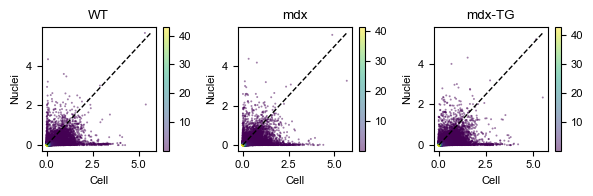

In [35]:
# figure, 3 plots, 1 row, 3 columns
fig, axes = plt.subplots(1, 3, figsize=(6, 6/3))

conditions = [
    ('WT', WT_cell_avg, WT_nuc_avg),
    ('mdx', mdx_cell_avg, mdx_nuc_avg),
    ('mdx-TG', TG_cell_avg, TG_nuc_avg)
]

for idx, (condition, cell_avg, nuc_avg) in enumerate(conditions):
    x_data = np.array(cell_avg).flatten()
    y_data = np.array(nuc_avg).flatten()
    
    c = gaussian_kde(np.vstack([x_data, y_data]))(np.vstack([x_data, y_data]))
    
    scatter = axes[idx].scatter(x_data, y_data, c=c, s=2, cmap='viridis', 
                                edgecolors='none', alpha=0.5, rasterized=True)

    
    max_val = max(x_data.max(), y_data.max())
    axes[idx].plot([0, max_val], [0, max_val], 'k--', lw=1)
    
    axes[idx].set_xlabel('Cell')
    axes[idx].set_ylabel('Nuclei')
    axes[idx].set_title(f'{condition}')
    plt.colorbar(scatter, ax=axes[idx])

plt.tight_layout()
plt.savefig("Figures/scatter plot expression by condition.svg", dpi=600, format='svg')
plt.show()

In [ ]:
avg_expr_cell = cell_only.X.mean(axis=0)
avg_expr_nuc = nuc_only.X.mean(axis=0)
gene_names = merged_data.var_names

plot_data = pd.DataFrame({
    'cell_avg': np.array(avg_expr_cell).flatten(),
    'nuc_avg': np.array(avg_expr_nuc).flatten()
}, index=gene_names)

plt.figure(figsize=(6, 6))
plt.scatter(x=plot_data['cell_avg'], y=plot_data['nuc_avg'], alpha=0.5, s=5) # 's' for point size
# plt.title('Average Gene Expression Between Two Samples')
plt.xlabel('cell')
plt.ylabel('nuclei')

# Add a 1:1 line for reference
max_val = max(plot_data['cell_avg'].max(), plot_data['nuc_avg'].max())
plt.plot([0, max_val], [0, max_val], 'k--', lw=2) # k-- is a black dashed line

plt.show()

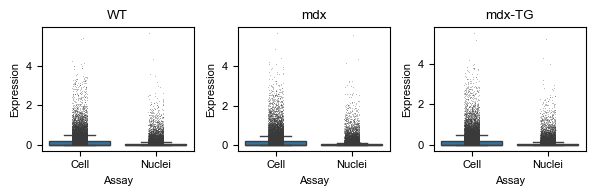

In [41]:
# figure, 3 plots, 1 row, 3 columns
fig, axes = plt.subplots(1, 3, figsize=(6, 6/3))

conditions = [
    ('WT', WT_cell_avg, WT_nuc_avg),
    ('mdx', mdx_cell_avg, mdx_nuc_avg),
    ('mdx-TG', TG_cell_avg, TG_nuc_avg)
]

for idx, (condition, cell_avg, nuc_avg) in enumerate(conditions):

    x_data = np.array(cell_avg).flatten()
    y_data = np.array(nuc_avg).flatten()

    xy = np.concatenate([x_data, y_data])
    assay = np.repeat(['Cell', 'Nuclei'], [len(x_data), len(y_data)])

    plot_data = pd.DataFrame({
        'Expression': xy,
        'Assay': assay
        })
    
    # sns.kdeplot(x='Expression', hue='Assay', data=plot_data, 
    #             ax=axes[idx], fill=True, common_norm=False, alpha=0.5)

    sns.boxplot(x='Assay', y='Expression',
                data=plot_data,
                ax=axes[idx],
                fliersize=0) 
    
    # sns.violinplot(x='Assay', y='Expression',
    #                data=plot_data,
    #                ax=axes[idx],
    #                inner=None,
    #                color=".8")

    sns.stripplot(x='Assay', y='Expression',
                  data=plot_data,
                  color=".3",
                  jitter=True,
                  rasterized=True,
                  alpha=0.5,
                  size=0.5,
                  ax=axes[idx])

    axes[idx].set_title(condition)

plt.tight_layout()
plt.savefig("Figures/boxplot_expression_by_condition.svg", dpi=600, format='svg')
plt.show()

In [ ]:
# figure, 3 plots, 1 row, 3 columns – boxplots per condition
fig, axes = plt.subplots(1, 3, figsize=(6, 6/3))

conditions = [
    ('WT', WT_cell_avg, WT_nuc_avg),
    ('mdx', mdx_cell_avg, mdx_nuc_avg),
    ('mdx-TG', TG_cell_avg, TG_nuc_avg)
]

for idx, (condition, cell_avg, nuc_avg) in enumerate(conditions):
    x_data = np.array(cell_avg).flatten()
    y_data = np.array(nuc_avg).flatten()

    plot_data = pd.DataFrame({
        'Expression': np.concatenate([x_data, y_data]),
        'Assay': np.repeat(['Cell', 'Nuclei'],
                           [len(x_data), len(y_data)])
    })

    sns.boxplot(x='Assay', y='Expression',
                data=plot_data,
                ax=axes[idx],
                fliersize=0)          # no outliers
    sns.stripplot(x='Assay', y='Expression',
                  data=plot_data,
                  color=".3",
                  jitter=True,
                  alpha=0.5,
                  size=1,
                  ax=axes[idx])

    axes[idx].set_title(condition)

plt.tight_layout()
plt.savefig("Figures/boxplot_expression_by_condition.svg",
            dpi=600, format='svg')
plt.show()

In [ ]:
gene_names = merged_data.var_names
cell_data = np.array(avg_expr_cell).flatten()
nuc_data = np.array(avg_expr_nuc).flatten()

avg_exp = np.concatenate([cell_data, nuc_data])

assay = np.repeat(['Cell', 'Nuclei'], [len(cell_data), len(nuc_data)])

plot_data = pd.DataFrame({
    'Expression': avg_exp,
    'Assay': assay
    })

p1 = sns.boxplot(x='Assay', y='Expression', data=plot_data, fliersize=0)

# sns.violinplot(x="Assay", y = "Expression", data=plot_data)

# Add jittered points using stripplot
sns.stripplot(x='Assay', y='Expression', 
              data=plot_data, 
              color=".3", 
              jitter=True, 
              alpha=0.5, 
              size=1)
plt.show()

---
<h1> FAPs only </h1>

In [ ]:
# load in datasets
FAPs_nuclei = ad.read_h5ad("FAPs.h5ad")
mdx_cell = ad.read_h5ad("mdx_FAPs_cell.h5ad")

In [ ]:
print(FAPs_nuclei.obs.columns)
print(FAPs_nuclei.obs["sample_id"].unique)

In [ ]:
# mdx only for nuclei
mdx_FAPs_nuc = FAPs_nuclei[FAPs_nuclei.obs["sample_id"] == "mdx"]

In [ ]:
# single cell processed by MA, raw counts are actually the normalized counts
# the .X slot is variable genes
# the .raw.X contains the normalized counts
# need to extract these
mdx_cell_X = mdx_cell.raw.X.copy()
mdx_cell_var = mdx_cell.raw.var.copy()

# put them into .X in a new anndata object
mdx_cell_new = sc.AnnData(X=mdx_cell_X, var=mdx_cell_var, obs=mdx_cell.obs)

# the genes in cell are all capital, change to match mouse convention
mdx_cell_new.var_names = mdx_cell_new.var_names.str.capitalize()

In [ ]:
# concatenate both datasets
both = {"cell": mdx_cell_new, 
        "nuclei": mdx_FAPs_nuc}
both_FAPs = ad.concat(both, join = "outer", label = "assay")

In [ ]:
# check example
sc.pl.violin(both_FAPs, ["Col1a1", "Col1a2"], multi_panel=True, groupby="assay")

In [ ]:
mdx_sc = both_FAPs[both_FAPs.obs["assay"] == "cell"]
mdx_nuc = both_FAPs[both_FAPs.obs["assay"] == "nuclei"]
avg_expr_cell = mdx_sc.X.mean(axis=0)
avg_expr_nuc = mdx_nuc.X.mean(axis=0)

In [ ]:
gene_names = both_FAPs.var_names
plot_data = pd.DataFrame({
    'cell_avg': np.array(avg_expr_cell).flatten(),
    'nuc_avg': np.array(avg_expr_nuc).flatten()
}, index=gene_names)

In [ ]:
plt.figure(figsize=(6, 6))
plt.scatter(x=plot_data['cell_avg'], y=plot_data['nuc_avg'], alpha=0.5, s=5) # 's' for point size
# plt.title('Average Gene Expression Between Two Samples')
plt.xlabel('cell')
plt.ylabel('nuclei')

# Add a 1:1 line for reference
max_val = max(plot_data['cell_avg'].max(), plot_data['nuc_avg'].max())
plt.plot([0, max_val], [0, max_val], 'k--', lw=2) # k-- is a black dashed line

plt.show()